# Topic: U.S. Presidential Election
Objective 1: Does the U.S. presidential election effectively act as a factor contributing extra volatility and returns to domestic equity market?

Objective 2: Does the election year affect Fama-French 3 factors' contributions to equity market returns?

In [1]:
# Only execute this for the first time
!pip install yfinance pandas

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [2]:
!pip install linearmodels

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 110.3 MB/s eta 0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.33 requires cython<3,>=0.27, but you have cython 3.0.11 which is incompatible.

[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python3 -m pip install --upgrade pip


## Step 1: Data Collection

In [3]:
# Import the necessary packages
import yfinance as yf
import pandas as pd
import datetime as dt 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_date = '1990-01-01'
end_date = '2024-10-20' # Today's date

In [4]:
# S&P500 historical data
ticker_symbol = '^GSPC'

# Download historical index from Yahoo Finance 
sp500 = yf.download(ticker_symbol,start=start_date, end=end_date)['Adj Close']

sp500_daily_returns = sp500.pct_change().fillna(0)
sp500_merged = pd.concat([sp500,sp500_daily_returns],axis=1)
sp500_merged.columns = ['sp500','sp500_daily_returns']
print(sp500_merged)

[*********************100%%**********************]  1 of 1 completed

                  sp500  sp500_daily_returns
Date                                        
1990-01-02   359.690002             0.000000
1990-01-03   358.760010            -0.002586
1990-01-04   355.670013            -0.008613
1990-01-05   352.200012            -0.009756
1990-01-08   353.790009             0.004514
...                 ...                  ...
2024-10-14  5859.850098             0.007708
2024-10-15  5815.259766            -0.007609
2024-10-16  5842.470215             0.004679
2024-10-17  5841.470215            -0.000171
2024-10-18  5864.669922             0.003972

[8767 rows x 2 columns]


In [5]:
# Dow Jones Composite Index historical data
ticker_symbol = '^DJI'

# Download historical index from Yahoo Finance 
djia = yf.download(ticker_symbol,start=start_date, end=end_date)['Adj Close']

djia_daily_returns = djia.pct_change().fillna(0)
djia_merged = pd.concat([djia,djia_daily_returns],axis=1)
djia_merged.columns = ['djia','djia_daily_returns']
print(djia_merged)

[*********************100%%**********************]  1 of 1 completed

                    djia  djia_daily_returns
Date                                        
1992-01-02   3172.399902            0.000000
1992-01-03   3201.500000            0.009173
1992-01-06   3200.100098           -0.000437
1992-01-07   3204.800049            0.001469
1992-01-08   3203.899902           -0.000281
...                  ...                 ...
2024-10-14  43065.218750            0.004698
2024-10-15  42740.421875           -0.007542
2024-10-16  43077.699219            0.007891
2024-10-17  43239.050781            0.003746
2024-10-18  43275.910156            0.000852

[8261 rows x 2 columns]


In [6]:
# Russell 2000 Index historical data
ticker_symbol = '^RUT'

# Download historical index from Yahoo Finance 
russell = yf.download(ticker_symbol,start=start_date, end=end_date)['Adj Close']

russell_daily_returns = russell.pct_change().fillna(0)
russell_merged = pd.concat([russell,russell_daily_returns],axis=1)
russell_merged.columns = ['russel','russell_daily_returns']
print(russell_merged)

[*********************100%%**********************]  1 of 1 completed

                 russel  russell_daily_returns
Date                                          
1990-01-02   169.949997               0.000000
1990-01-03   170.789993               0.004943
1990-01-04   170.089996              -0.004099
1990-01-05   169.649994              -0.002587
1990-01-08   169.550003              -0.000589
...                 ...                    ...
2024-10-14  2248.639893               0.006369
2024-10-15  2249.820068               0.000525
2024-10-16  2286.679932               0.016383
2024-10-17  2280.850098              -0.002549
2024-10-18  2276.090088              -0.002087

[8767 rows x 2 columns]


In [7]:
# NASDAC Composite Index historical data
ticker_symbol = '^IXIC'

# Download historical index from Yahoo Finance 
nasd = yf.download(ticker_symbol,start=start_date, end=end_date)['Adj Close']

nasd_daily_returns = nasd.pct_change().fillna(0)
nasd_merged = pd.concat([nasd,nasd_daily_returns],axis=1)
nasd_merged.columns = ['nasdac','nasdac_daily_returns']
print(nasd_merged)

[*********************100%%**********************]  1 of 1 completed

                  nasdac  nasdac_daily_returns
Date                                          
1990-01-02    459.299988              0.000000
1990-01-03    460.899994              0.003484
1990-01-04    459.399994             -0.003255
1990-01-05    458.200012             -0.002612
1990-01-08    458.700012              0.001091
...                  ...                   ...
2024-10-14  18502.689453              0.008709
2024-10-15  18315.589844             -0.010112
2024-10-16  18367.080078              0.002811
2024-10-17  18373.609375              0.000355
2024-10-18  18489.550781              0.006310

[8767 rows x 2 columns]


In [8]:
# Volatility index as the volatility factor data proxy
ticker_symbol = '^VIX' 
vix = yf.download(ticker_symbol,start=start_date, end=end_date)['Adj Close']

vix_daily_returns = vix.pct_change().fillna(0)
vix_merged = pd.concat([vix,vix_daily_returns],axis=1)
vix_daily_returns.columns = ['vix']
vix_merged.columns = ['vix','vix_daily_returns']
print(vix_daily_returns)
print(vix_merged)

[*********************100%%**********************]  1 of 1 completed

Date
1990-01-02    0.000000
1990-01-03    0.055104
1990-01-04    0.056624
1990-01-05    0.046306
1990-01-08    0.007459
                ...   
2024-10-14   -0.037146
2024-10-15    0.047716
2024-10-16   -0.051357
2024-10-17   -0.024004
2024-10-18   -0.056515
Name: Adj Close, Length: 8767, dtype: float64
                  vix  vix_daily_returns
Date                                    
1990-01-02  17.240000           0.000000
1990-01-03  18.190001           0.055104
1990-01-04  19.219999           0.056624
1990-01-05  20.110001           0.046306
1990-01-08  20.260000           0.007459
...               ...                ...
2024-10-14  19.700001          -0.037146
2024-10-15  20.639999           0.047716
2024-10-16  19.580000          -0.051357
2024-10-17  19.110001          -0.024004
2024-10-18  18.030001          -0.056515

[8767 rows x 2 columns]


In [9]:
# Import data of unemployment rate in percentage
unemploy_rate = pd.read_csv("US Unemployment Rate.csv", parse_dates=['DATE'], index_col='DATE')
print(unemploy_rate)

# Import data of US Core PCE as inflation data
inflation = pd.read_csv("US Core PCE.csv", parse_dates=['DATE'], index_col='DATE')
print(inflation)

# Import data of US Fed Rate as Interest Rate
int_rate = pd.read_csv("US Fed Rates.csv", parse_dates=['DATE'], index_col='DATE')
print(int_rate)

# Import data of election data (incumbent won = 1, challenger won = 0) 
incumbent_won = pd.read_csv("Incumbency in Election Years.csv", 
usecols =[0, 3], index_col='Years')
print(incumbent_won)

            UNRATE
DATE              
1990-01-01     5.4
1990-02-01     5.3
1990-03-01     5.2
1990-04-01     5.4
1990-05-01     5.4
...            ...
2024-05-01     4.0
2024-06-01     4.1
2024-07-01     4.3
2024-08-01     4.2
2024-09-01     4.1

[417 rows x 1 columns]
            CORE_PCE
DATE                
1990-01-01    59.181
1990-02-01    59.468
1990-03-01    59.754
1990-04-01    59.932
1990-05-01    60.115
...              ...
2024-04-01   122.140
2024-05-01   122.239
2024-06-01   122.510
2024-07-01   122.703
2024-08-01   122.863

[416 rows x 1 columns]
            FED_RATES
DATE                 
1990-01-01       8.23
1990-02-01       8.24
1990-03-01       8.28
1990-04-01       8.26
1990-05-01       8.18
...               ...
2024-05-01       5.33
2024-06-01       5.33
2024-07-01       5.33
2024-08-01       5.33
2024-09-01       5.13

[417 rows x 1 columns]
       incumbent_won
Years               
1990               1
1992               1
1996               0
2000             

## Step 2: Data Wrangling

In [10]:
# Log-transform inflation each year
log_inflation = np.log(inflation['CORE_PCE'])

# Resample the log-transformed inflation data to daily frequency and forward fill the values
log_inflation_daily = log_inflation.resample('D').ffill()

# Forward fill the values to the end of August 2024
end_date = '2024-08-31'
if log_inflation_daily.index[-1] < pd.to_datetime(end_date):
    last_value = log_inflation_daily.iloc[-1]
    new_index = pd.date_range(start=log_inflation_daily.index[-1] + pd.Timedelta(days=1), end=end_date, freq='D')
    new_values = pd.Series(last_value, index=new_index)
    log_inflation_daily = pd.concat([log_inflation_daily, new_values])
    
# Log-transform VIX
log_vix = np.log(vix)

# Resample the log-transformed VIX data to daily frequency and forward fill the values
log_vix_daily = log_vix.resample('D').ffill()

# Log-transform S&P 500
log_sp500 = np.log(sp500)

# Resample the log-transformed S&P 500 data to daily frequency and forward fill the values
log_sp500_daily = log_sp500.resample('D').ffill()

In [11]:
# Resample unemployment rate to daily frequency using forward fill
unemploy_rate_daily = unemploy_rate.resample('D').ffill()

# Resample interest (policy) rate to daily frequency using forward fill
int_rate_daily = int_rate.resample('D').ffill()

# Forward fill incumbent_won for their respective years only
incumbent_won = incumbent_won.reindex(range(incumbent_won.index.min(), 2025), method='ffill')
incumbent_won

,incumbent_won
Years,
1990,1
1991,1
1992,1
1993,1
1994,1
1995,1
1996,0
1997,0
1998,0


In [12]:
# Merge the dataframes
daily_chg = pd.concat([log_sp500_daily, unemploy_rate_daily, log_inflation_daily, log_vix_daily, int_rate_daily], axis=1)
daily_chg.columns = ['log_sp500','unemploy_rate',  'log_inflation','log_vix','int_rate_daily']

# Take daily_chg to only end of 2024-Aug
daily_chg = daily_chg.loc['1990-01-02':'2024-08-31']
daily_chg.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12661 entries, 1990-01-02 to 2024-08-31
Freq: D
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   log_sp500       12661 non-null  float64
 1   unemploy_rate   12661 non-null  float64
 2   log_inflation   12661 non-null  float64
 3   log_vix         12661 non-null  float64
 4   int_rate_daily  12661 non-null  float64
dtypes: float64(5)
memory usage: 593.5 KB


In [13]:
# Define election years from 1992 to 2024
election_years = list(range(1992, 2025, 4))

# Create a new column 'election' in the daily_chg dataframe
daily_chg['election'] = daily_chg.index.year.isin(election_years).astype(int)

# Reorder columns to place 'election' between 'sp500_daily_chg' and 'unemploy_rate_daily'
cols = daily_chg.columns.tolist()
election_index = cols.index('log_sp500') + 1
cols.insert(election_index, cols.pop(cols.index('election')))
daily_chg = daily_chg[cols]

# Display the updated dataframe
daily_chg

,log_sp500,election,unemploy_rate,log_inflation,log_vix,int_rate_daily
1990-01-02,5.885243,0,5.4,4.080601,2.847232,8.23
1990-01-03,5.882654,0,5.4,4.080601,2.900872,8.23
1990-01-04,5.874003,0,5.4,4.080601,2.955951,8.23
1990-01-05,5.864199,0,5.4,4.080601,3.001217,8.23
1990-01-06,5.864199,0,5.4,4.080601,3.001217,8.23
...,...,...,...,...,...,...
2024-08-27,8.635118,1,4.2,4.811070,2.736314,5.33
2024-08-28,8.629125,1,4.2,4.811070,2.839663,5.33
2024-08-29,8.629085,1,4.2,4.811070,2.750471,5.33
2024-08-30,8.639128,1,4.2,4.811070,2.708050,5.33


In [14]:
# Create a new column 'year' in the 'daily_chg' dataframe to facilitate merging
daily_chg['year'] = daily_chg.index.year

# Merge the 'incumbent_won' column with the 'daily_chg' dataframe based on the 'year' column
daily_chg = daily_chg.merge(incumbent_won, left_on='year', right_index=True, how='left')

# Drop the 'year' column as it is no longer needed
daily_chg.drop(columns=['year'], inplace=True)

# Reorder columns to place 'incumbent_won' between 'election' and 'unemploy_rate_daily'
cols = daily_chg.columns.tolist()
election_idx = cols.index('election')
cols.insert(election_idx + 1, cols.pop(cols.index('incumbent_won')))
daily_chg = daily_chg[cols]

daily_chg

,log_sp500,election,incumbent_won,unemploy_rate,log_inflation,log_vix,int_rate_daily
1990-01-02,5.885243,0,1,5.4,4.080601,2.847232,8.23
1990-01-03,5.882654,0,1,5.4,4.080601,2.900872,8.23
1990-01-04,5.874003,0,1,5.4,4.080601,2.955951,8.23
1990-01-05,5.864199,0,1,5.4,4.080601,3.001217,8.23
1990-01-06,5.864199,0,1,5.4,4.080601,3.001217,8.23
...,...,...,...,...,...,...,...
2024-08-27,8.635118,1,0,4.2,4.811070,2.736314,5.33
2024-08-28,8.629125,1,0,4.2,4.811070,2.839663,5.33
2024-08-29,8.629085,1,0,4.2,4.811070,2.750471,5.33
2024-08-30,8.639128,1,0,4.2,4.811070,2.708050,5.33


In [15]:
# Checking data
daily_chg.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12661 entries, 1990-01-02 to 2024-08-31
Freq: D
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   log_sp500       12661 non-null  float64
 1   election        12661 non-null  int64  
 2   incumbent_won   12661 non-null  int64  
 3   unemploy_rate   12661 non-null  float64
 4   log_inflation   12661 non-null  float64
 5   log_vix         12661 non-null  float64
 6   int_rate_daily  12661 non-null  float64
dtypes: float64(5), int64(2)
memory usage: 791.3 KB


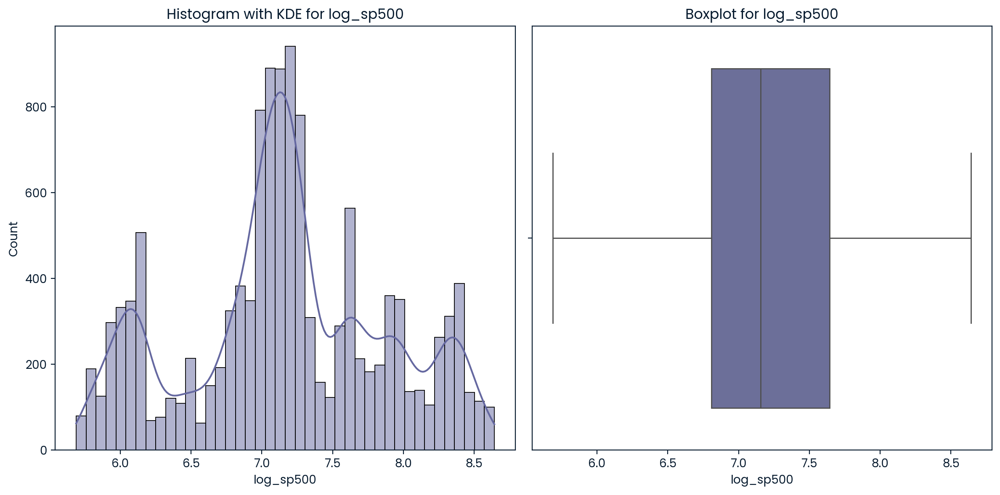

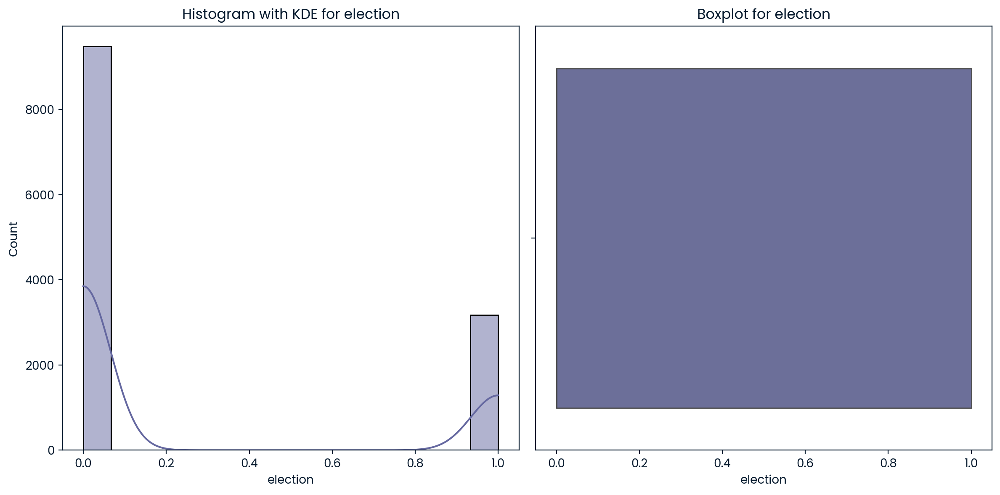

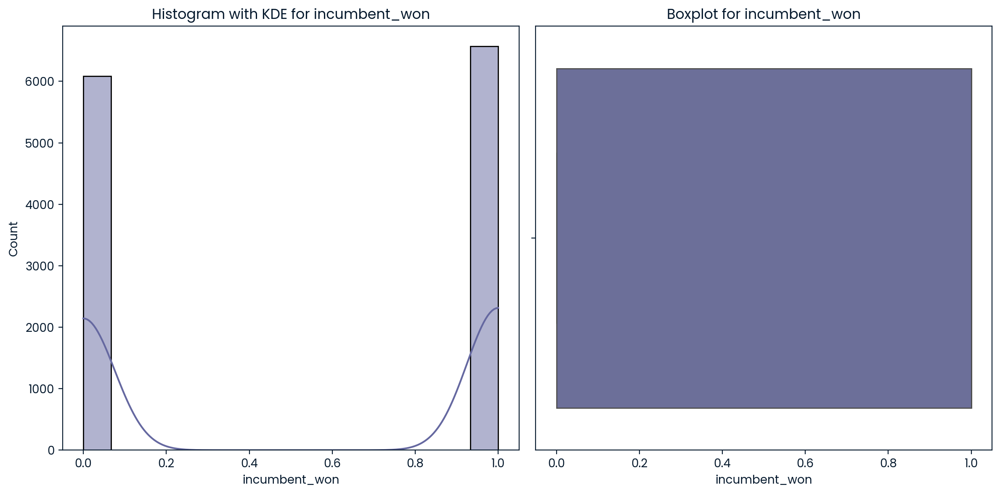

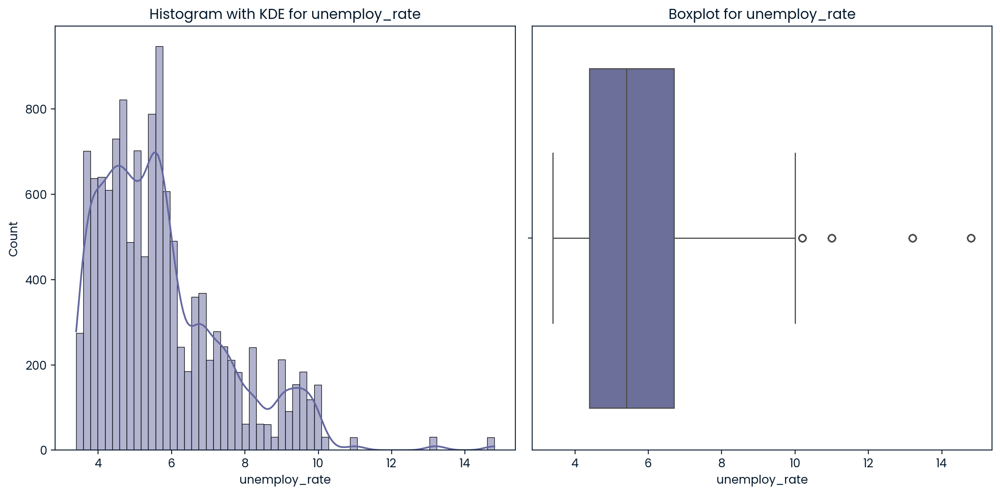

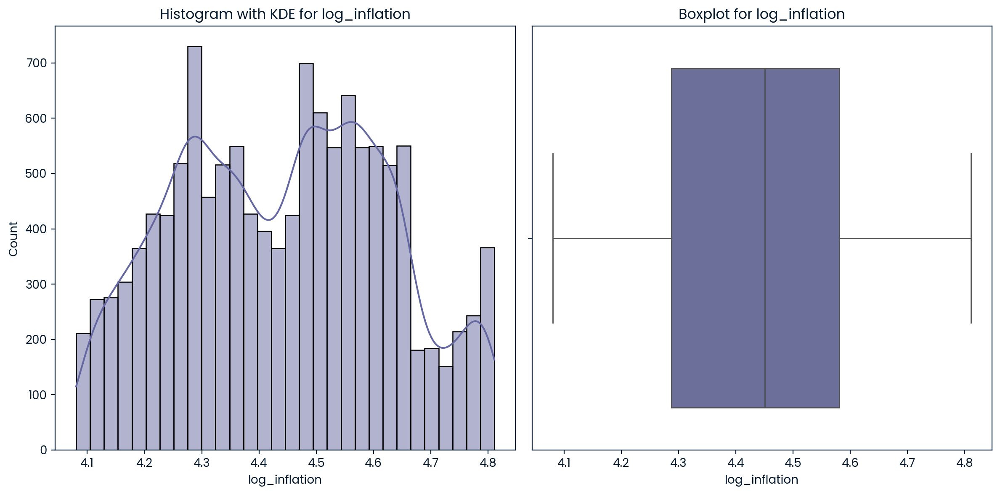

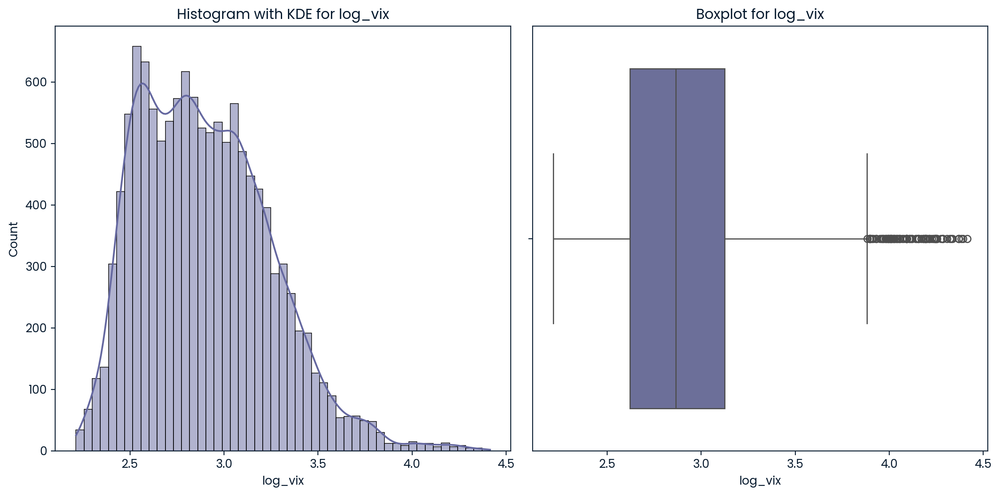

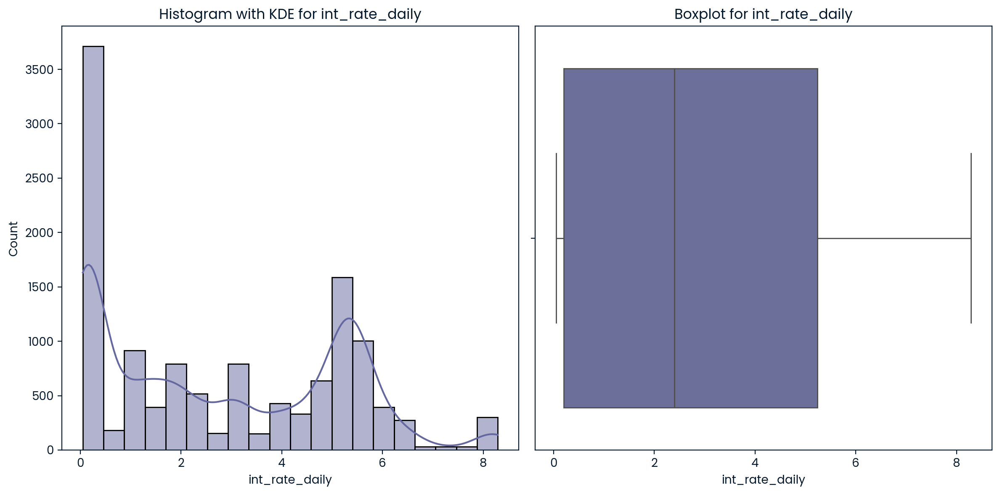

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Function to plot distribution check for each variable
def plot_distribution_check(data, column_name):
    plt.figure(figsize=(12, 6))
    
    # Histogram with KDE
    plt.subplot(1, 2, 1)
    sns.histplot(data[column_name], kde=True)
    plt.title(f'Histogram with KDE for {column_name}')
    
    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=data[column_name])
    plt.title(f'Boxplot for {column_name}')
    
    plt.tight_layout()
    plt.show()

# For each column in the daily_chg dataframe
for column in daily_chg.columns:
    plot_distribution_check(daily_chg, column)

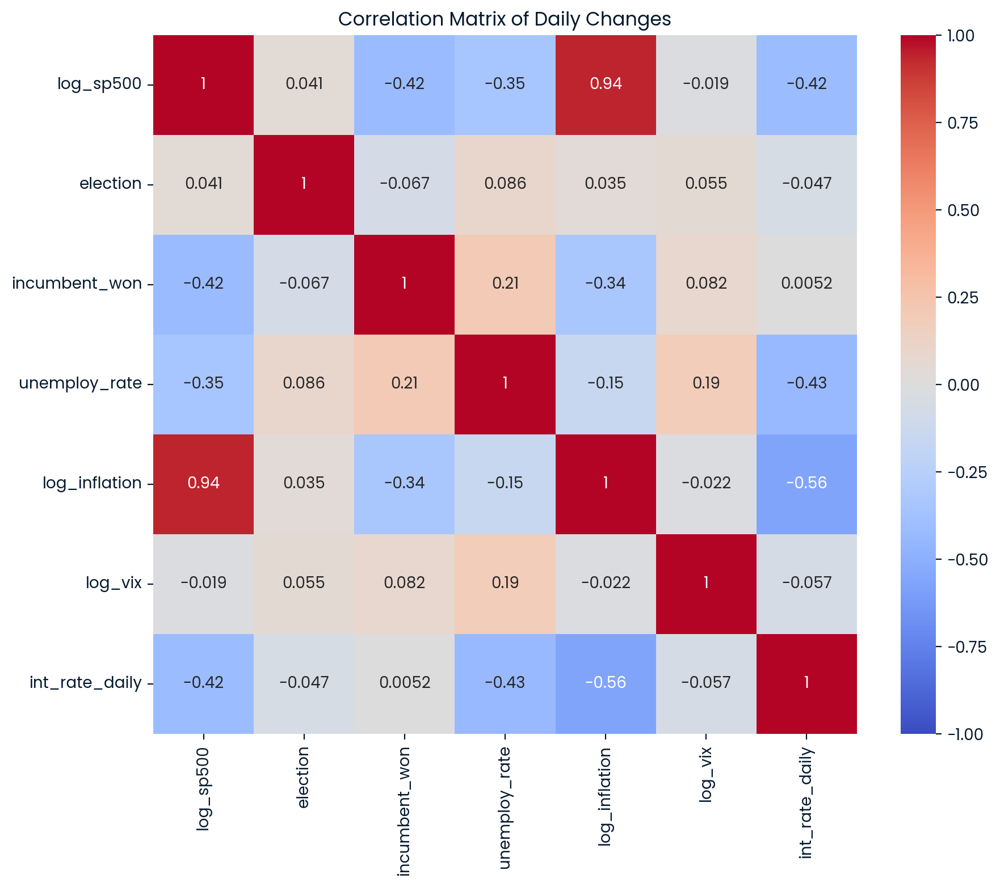

In [17]:
import seaborn as sns

# Calculate the Pearson correlation coefficient between variables in daily_chg
correlation_matrix = daily_chg.corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Daily Changes')
plt.show()

#### The correlation between vix and sp500, that would be helpful that we found one potential factor that leads to higher market returns. All Xs are not highly correlated with each other according to the correlation matrix, to avoid multicollinearity issue.

## Step 3: Construct Regression Models and Test Hypothesis

### Hypothesis 1: Volatility and Return Analysis

In [51]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Define the dependent variable (Y)
Y = daily_chg['log_sp500']

# Define the independent variables (X)
X = daily_chg[['election','incumbent_won','unemploy_rate', 'log_inflation','log_vix','int_rate_daily']]

# Add a constant to the independent variables
X = sm.add_constant(X)

# Perform OLS regression with Newey-West standard errors
model = sm.OLS(Y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 1})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_sp500   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                 2.672e+04
Date:                Fri, 08 Nov 2024   Prob (F-statistic):               0.00
Time:                        05:44:31   Log-Likelihood:                 4800.2
No. Observations:               12661   AIC:                            -9586.
Df Residuals:                   12654   BIC:                            -9534.
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -7.2963      0.114    -64.

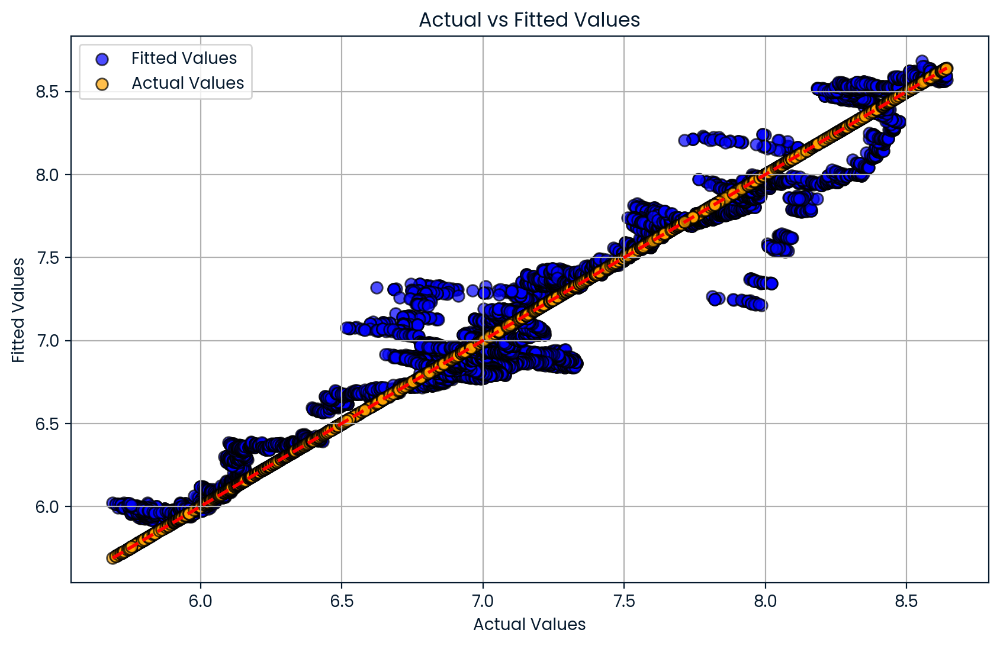

In [19]:
import matplotlib.pyplot as plt

# Extract the fitted values and the actual values
fitted_values = model.fittedvalues
actual_values = Y

# Plot the actual values vs. fitted values
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, fitted_values, edgecolor='k', alpha=0.7, s=50, label='Fitted Values', color='blue')
plt.scatter(actual_values, actual_values, edgecolor='k', alpha=0.7, s=50, label='Actual Values', color='orange')
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Fitted Values')
plt.title('Actual vs Fitted Values')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# Test multicollinearity by calculate VIF for each explanatory variable
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Display VIF data and F-test results
vif_data

,feature,VIF
0,const,1695.208131
1,election,1.017969
2,incumbent_won,1.206354
3,unemploy_rate,1.789062
4,log_inflation,2.321900
5,log_vix,1.043062
6,int_rate_daily,2.545427


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm

# Function to plot residual analysis plots for the whole model
def plot_residuals_analysis(model):
    residuals = model.resid
    
    plt.figure(figsize=(18, 12))
    
    # Q-Q plot
    plt.subplot(2, 2, 1)
    sm.qqplot(residuals, line='s', ax=plt.gca())
    plt.title('Q-Q plot for residuals of the model')
    
    # Histogram
    plt.subplot(2, 2, 2)
    sns.histplot(residuals, kde=True)
    plt.title('Histogram for residuals of the model')
    
    # Residuals vs Fitted
    plt.subplot(2, 2, 3)
    fitted_values = model.fittedvalues
    sns.scatterplot(x=fitted_values, y=residuals)
    plt.axhline(0, color='r', linestyle='--')
    plt.title('Residuals vs Fitted for the model')
    plt.xlabel('Fitted values')
    plt.ylabel('Residuals')
    
    # Scale-Location plot
    plt.subplot(2, 2, 4)
    sqrt_abs_residuals = np.sqrt(np.abs(residuals))
    sns.scatterplot(x=fitted_values, y=sqrt_abs_residuals)
    plt.axhline(0, color='r', linestyle='--')
    plt.title('Scale-Location plot for the model')
    plt.xlabel('Fitted values')
    plt.ylabel('Sqrt(|Residuals|)')
    
    plt.tight_layout()
    plt.show()


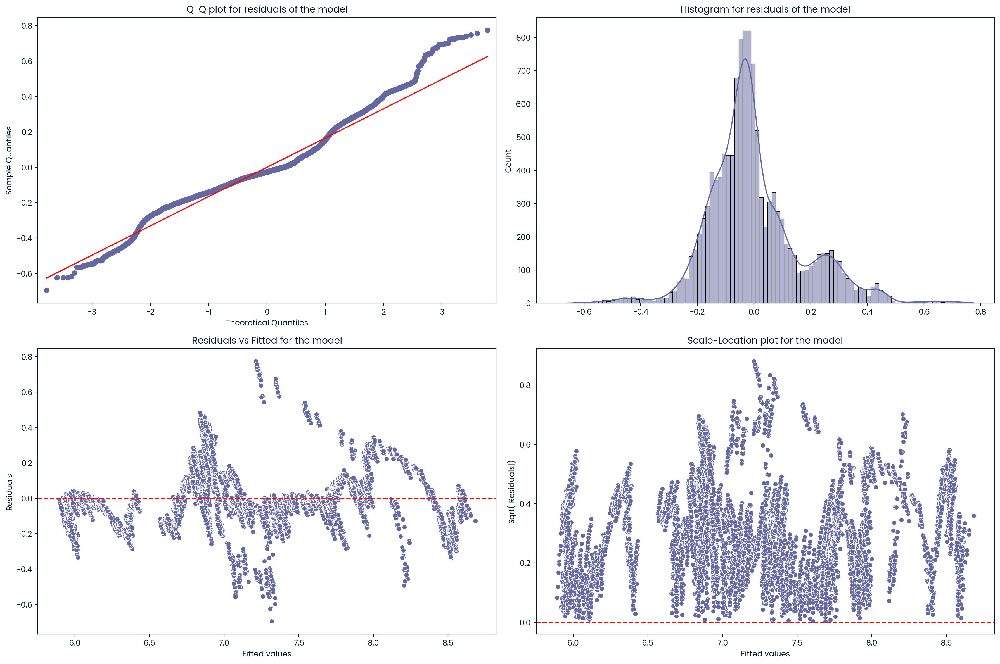

In [22]:
plot_residuals_analysis(model)

In [23]:
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.diagnostic import het_white
from statsmodels.stats.diagnostic import linear_harvey_collier

def test_assum(model):
    
    # Test homoskedasticity using Breusch-Pagan (BP) Test
    test_result = het_breuschpagan(model.resid, model.model.exog)
    print('Lagrange multiplier statistic:', test_result[0])
    print('p-value:', test_result[1])
    # If the p-value is less than 0.05, we reject the null hypothesis of homoskedasticity
    if test_result[1] < 0.05:
        print("Breusch-Pagan Test: The residuals are heteroskedastic (p < 0.05).")
    else:
        print("Breusch-Pagan Test: The residuals are homoskedastic (p >= 0.05).")
    
    # Calculate residuals
    residuals = model.resid

    # Perform Shapiro-Wilk test for normality on the residuals
    shapiro_test = stats.shapiro(residuals)

    # Extract the test statistic and p-value
    shapiro_statistic, shapiro_p_value = shapiro_test
    print(shapiro_test)
    # If the p-value is less than 0.05, we reject the null hypothesis of normality
    if shapiro_p_value < 0.05:
        print("Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).")
    else:
        print("Shapiro-Wilk Test: The residuals are normally distributed (p >= 0.05).")

Lagrange multiplier statistic: 3920.972213347728
p-value: 0.0
Breusch-Pagan Test: The residuals are heteroskedastic (p < 0.05).
ShapiroResult(statistic=0.9509445428848267, pvalue=0.0)
Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).


(0.010005999280370863, <Figure size 640x480 with 1 Axes>)

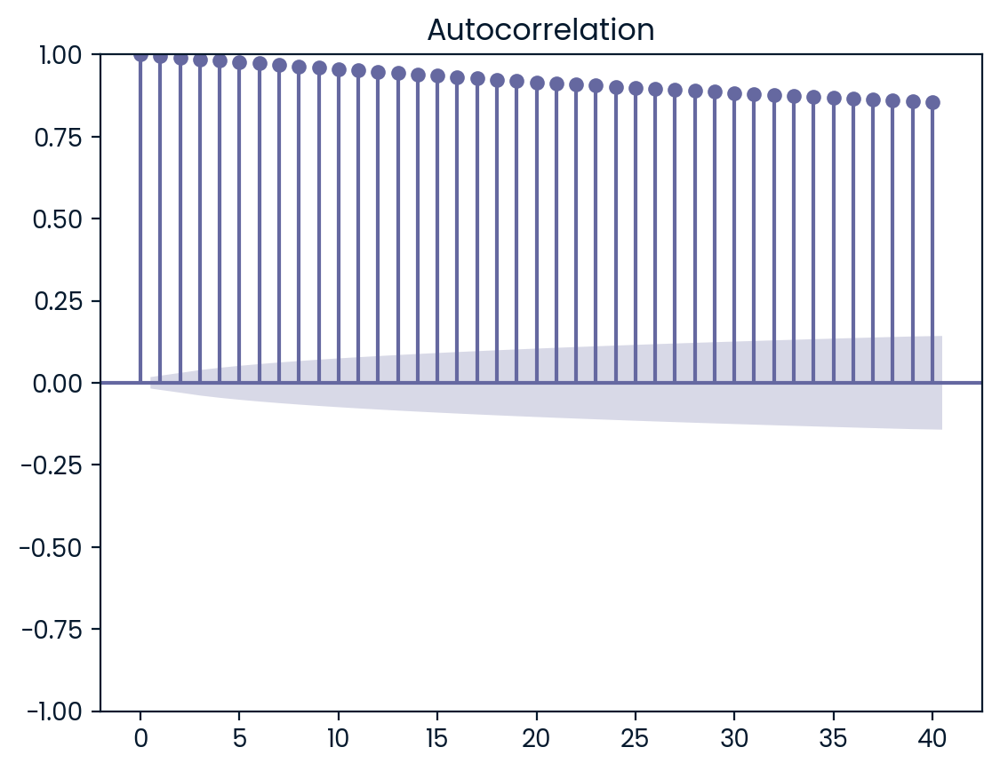

In [24]:
test_assum(model)

from statsmodels.stats.stattools import durbin_watson
import statsmodels.api as sm

# Perform Durbin-Watson test on model3 residuals
dw_test = durbin_watson(model.resid)

# Perform ACF test on model3 residuals
acf_test = sm.graphics.tsa.plot_acf(model.resid, lags=40)

dw_test, acf_test

In [25]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# Define the unrestricted model
unrestricted_model = ols('log_sp500 ~ election + incumbent_won + unemploy_rate + log_inflation + log_vix + int_rate_daily', data=daily_chg).fit(cov_type='HAC', cov_kwds={'maxlags':1})

# Define the restricted model (excluding election and incumbent_won)
restricted_model = ols('log_sp500 ~ unemploy_rate + log_inflation + log_vix + int_rate_daily', data=daily_chg).fit(cov_type='HAC', cov_kwds={'maxlags':1})

# Perform F-test to compare the restricted and unrestricted models
anova_results = anova_lm(restricted_model, unrestricted_model)

# Display the ANOVA results
print(anova_results)

# Conclusion based on the p-value
if anova_results["Pr(>F)"][1] < 0.05:
    conclusion = "The unrestricted model is significantly better than the restricted model."
else:
    conclusion = "There is no significant difference between the restricted and unrestricted models."

# Additional conclusion
additional_conclusion = "The robust covariance treatment accounts for heteroskedasticity and autocorrelation, providing more reliable test results."

print(conclusion, additional_conclusion)

   df_resid         ssr  df_diff    ss_diff           F  Pr(>F)
0   12656.0  391.665189      0.0        NaN         NaN     NaN
1   12654.0  347.279943      2.0  44.385246  808.642883     0.0
The unrestricted model is significantly better than the restricted model. The robust covariance treatment accounts for heteroskedasticity and autocorrelation, providing more reliable test results.


#### The above model (Model 1) shows autocorrelation issue, potentially inflating its variance and making the inference process (hypothesis testing for each coefficient) unreliable. We then apply Newey-West standard error (a more robust standard error) to reduce the influence of autocorrelation and heterosedasticity without making this an AR model.

#### Our findings: All variables including election (1 for election year, 0 for non-election year), incumbent_won, unemploy_rate, log_inflation (log-PCE data), log_vix (inflation proxy), and interest rate.

#### Additionally, we also make comparison between restricted (election and incumbent_won variables excluded from model 1) and unrestricted (full model 1), and the result shows that both variables are significant to be included in our model and thus, we think they do offer more predictive power to our model.

#### Experiment: Let's try applying LASSO regularization to the model to identify the most important factor to sp500 index changes.

In [26]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
import numpy as np

# Define the features and target variable
X = X.drop(columns=['const'])
y = daily_chg['log_sp500']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform LassoCV to find the best alpha
lasso_cv = LassoCV(cv=5, random_state=0).fit(X_scaled, y)

# Get the best alpha
best_alpha = lasso_cv.alpha_

# Fit the Lasso model with the best alpha
lasso_model = LassoCV(alphas=[best_alpha], cv=5, random_state=0).fit(X_scaled, y)

# Coefficients of the Lasso model
lasso_coefficients = lasso_model.coef_

# Intercept of the Lasso model
lasso_intercept = lasso_model.intercept_

# Display the results
lasso_coefficients, lasso_intercept, best_alpha

# Interpretation:
# The coefficients (lasso_coefficients) represent the impact of each standardized feature on the log of the S&P 500 daily change.
# The intercept (lasso_intercept) is the expected log of the S&P 500  when all standardized features are zero.
# The best alpha (best_alpha) is the regularization strength that was selected by cross-validation to minimize the model's error.

(array([ 0.        , -0.04986462, -0.12901123,  0.61448109,  0.01155589,
        -0.        ]),
 7.170275673164129,
 0.01652966600009087)

### Discovering interactive terms

In [56]:
import statsmodels.api as sm

# Define the dependent variable Y
Y = daily_chg['log_sp500']

# Define the independent variables X (including log_vix and interaction terms)
X = daily_chg[['log_vix', 'election', 'incumbent_won', 'unemploy_rate', 'log_inflation', 'int_rate_daily']]

# Create interaction terms
X['election*incumbent_won'] = X['election'] * X['incumbent_won']  
X['election*unemploy_rate'] = X['election'] * X['unemploy_rate']
X['election*log_inflation'] = X['election'] * X['log_inflation']
X['election*int_rate_daily'] = X['election'] * X['int_rate_daily']
X['election*log_vix'] = X['election'] * X['log_vix']

# Add a constant to the independent variables
X = sm.add_constant(X)

# Create the regression model using robust covariance for heteroskedasticity, autocorrelation, and multicollinearity
model2 = sm.OLS(Y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 1})

# Display the summary of the regression model
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_sp500   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                 1.823e+04
Date:                Fri, 08 Nov 2024   Prob (F-statistic):               0.00
Time:                        05:49:07   Log-Likelihood:                 6066.8
No. Observations:               12661   AIC:                        -1.211e+04
Df Residuals:                   12649   BIC:                        -1.202e+04
Df Model:                          11                                         
Covariance Type:                  HAC                                         
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -5.4362      0.084    -64.345      0.000      -5.602      -5.271
log_vix                     0.0853      0.007     12.797      0.000       0.072       0.098
election                   -4.3686      0.181    -24.109      0.000      -4.724      -4.013
incumbent_won              -0.1513      0.004    -37.059      0.000      -0.159      -0.143
unemploy_rate              -0.1198      0.002    -72.073      0.000      -0.123      -0.117
log_inflation               2.9793      0.016    180.643      0.000       2.947       3.012
int_rate_daily             -0.0402      0.001    -33.044      0.000      -0.043      -0.038
election*incumbent_won      0.1416      0.009     15.790      0.000       0.124       0.159
election*unemploy_rate      0.0934      0.004     21.907      0.000       0.085       0.102
election*log_inflation      0.8036      0.036     22.240      0.000       0.733       0.874
election*int_rate_daily     0.0953      0.003     29.477      0.000       0.089       0.102
election*log_vix           -0.0154      0.023     -0.681      0.496      -0.060       0.029
==============================================================================
Omnibus:                      161.993   Durbin-Watson:                   0.010
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              171.748
Skew:                           0.260   Prob(JB):                     5.07e-38
Kurtosis:                       3.235   Cond. No.                         833.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 1 lags and without small sample correction
"""

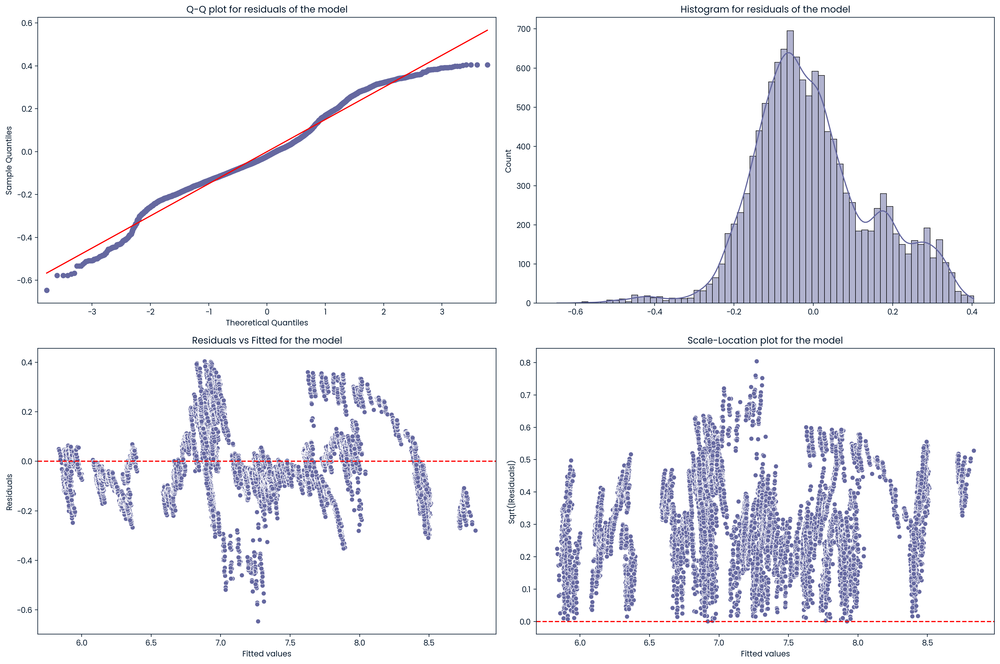

Lagrange multiplier statistic: 4578.045167285805
p-value: 0.0
Breusch-Pagan Test: The residuals are heteroskedastic (p < 0.05).
ShapiroResult(statistic=0.9767506122589111, pvalue=6.442749949426211e-41)
Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).


In [57]:
plot_residuals_analysis(model2)
test_assum(model2)

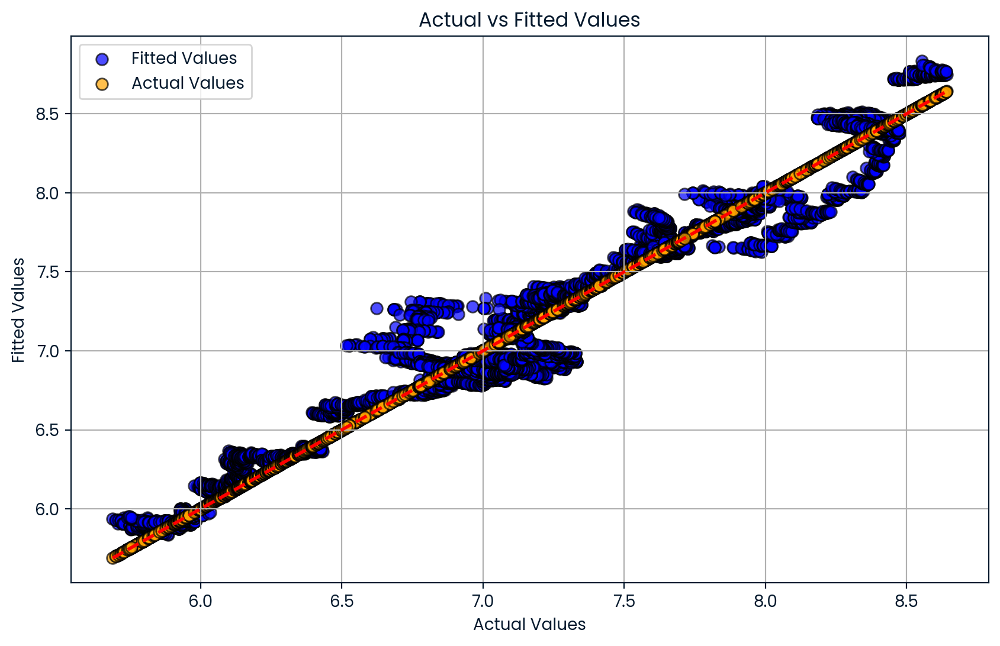

In [58]:
fitted_values = model2.fittedvalues
actual_values = Y

# Plot the actual values vs. fitted values
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, fitted_values, edgecolor='k', alpha=0.7, s=50, label='Fitted Values', color='blue')
plt.scatter(actual_values, actual_values, edgecolor='k', alpha=0.7, s=50, label='Actual Values', color='orange')
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Fitted Values')
plt.title('Actual vs Fitted Values')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
import numpy as np

# Define the features and target variable
X = X.drop(columns=['const'])
y = daily_chg['log_sp500']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform LassoCV to find the best alpha
lasso_cv = LassoCV(cv=5, random_state=0).fit(X_scaled, y)

# Get the best alpha
best_alpha = lasso_cv.alpha_

# Fit the Lasso model with the best alpha
lasso_model = LassoCV(alphas=[best_alpha], cv=5, random_state=0).fit(X_scaled, y)

# Coefficients of the Lasso model
lasso_coefficients = lasso_model.coef_

# Intercept of the Lasso model
lasso_intercept = lasso_model.intercept_

# Display the results
lasso_coefficients, lasso_intercept, best_alpha

# Interpretation:
# The coefficients (lasso_coefficients) represent the impact of each standardized feature on the log of the S&P 500 daily change.
# The intercept (lasso_intercept) is the expected log of the S&P 500  when all standardized features are zero.
# The best alpha (best_alpha) is the regularization strength that was selected by cross-validation to minimize the model's error.

(array([ 0.01138086,  0.        , -0.04975745, -0.12697961,  0.61633382,
        -0.        ,  0.        ,  0.        ,  0.        ,  0.0122146 ,
         0.        ]),
 7.170275673164129,
 0.01652966600009087)

#### With L1 regularization, we eliminate less important (may include statistically significant) factors in our model to reduce variance (overfit) by minimally increase bias (underfit). This resulted in retention of factors including log_vix, incumbent_won, unemployment rate, log_inflation, and interaction term of election and interest rate.

In [30]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Predict the target variable using the Lasso model
y_pred = lasso_model.predict(X_scaled)

# Calculate the R-squared value
r_squared = r2_score(y, y_pred)

# Calculate the RMSE value
rmse = np.sqrt(mean_squared_error(y, y_pred))
exp_rmse =  np.exp(rmse)

# Display the R-squared and RMSE values
r_squared, exp_rmse

(0.9435134966193248, 1.1827701180812564)

### Since the interaction term of election & log_vix is statistically insignificant, we can conclude it is not statistically significant that the election periods do have a distinctive or amplified effect on VIX movements compared to non-election periods, at least in our research timeframe of 25 years.

### Rationale: Though more extensive research should be done to conclude the rationales behind the insignificance, we think it is potentially because:


(To be rephrase, AI-gen contents)
#### i) Elections Are Anticipated Events: Since elections are predictable and occur on regular cycles, markets have time to adjust well in advance. Investors often price in potential volatility or uncertainty related to elections months before the election year, which may reduce any unique impact during the actual election period.

#### ii) Pre-Election Hedging: Investors may hedge against election-related risks beforehand, dampening any spike in volatility closer to the election itself. This hedging can reduce short-term volatility as measured by the VIX, making election-year effects less prominent in the data.

#### iii) Other Economic Factors Overshadow Elections: Economic indicators like inflation, interest rates, and unemployment could have a stronger influence on market volatility than the election itself. If these factors are driving most of the VIX's variation, any additional effect of the election could appear weak or insignificant.

### Comparing election and non-election year returns:

In [31]:
# Calculate the annual S&P 500 by taking the ending value of each year
annual_sp500 = sp500.resample('Y').last()

# Calculate the percentage change of annual S&P 500
annual_sp500_pct_change = annual_sp500.pct_change()
annual_sp500_pct_change = annual_sp500_pct_change.fillna(0)
annual_sp500_pct_change

Date
1990-12-31    0.000000
1991-12-31    0.263067
1992-12-31    0.044643
1993-12-31    0.070552
1994-12-31   -0.015393
1995-12-31    0.341107
1996-12-31    0.202637
1997-12-31    0.310082
1998-12-31    0.266686
1999-12-31    0.195260
2000-12-31   -0.101392
2001-12-31   -0.130427
2002-12-31   -0.233660
2003-12-31    0.263804
2004-12-31    0.089935
2005-12-31    0.030010
2006-12-31    0.136194
2007-12-31    0.035296
2008-12-31   -0.384858
2009-12-31    0.234542
2010-12-31    0.127827
2011-12-31   -0.000032
2012-12-31    0.134057
2013-12-31    0.296012
2014-12-31    0.113906
2015-12-31   -0.007266
2016-12-31    0.095350
2017-12-31    0.194200
2018-12-31   -0.062373
2019-12-31    0.288781
2020-12-31    0.162589
2021-12-31    0.268927
2022-12-31   -0.194428
2023-12-31    0.242305
2024-12-31    0.229534
Freq: YE-DEC, Name: Adj Close, dtype: float64

In [32]:
# Define election years from 1992 to 2024
election_years = list(range(1992, 2025, 4))

# Filter the annual returns for election years and non-election years
election_years_returns = annual_sp500_pct_change[annual_sp500_pct_change.index.year.isin(election_years)]
non_election_years_returns = annual_sp500_pct_change[~annual_sp500_pct_change.index.year.isin(election_years)]

# Calculate mean and median for election years
mean_election_years = election_years_returns.mean()
median_election_years = election_years_returns.median()

# Calculate mean and median for non-election years
mean_non_election_years = non_election_years_returns.mean()
median_non_election_years = non_election_years_returns.median()

print(f"In %:-\nElection-year mean return: {mean_election_years*100},\nElection-year median return: {median_election_years*100},\nNon-election year mean return: {mean_non_election_years*100},\nNon-election year median return: {median_non_election_years*100}")

In %:-
Election-year mean return: 5.24994173560773,
Election-year median return: 9.535022667283656,
Non-election year mean return: 11.673000155892959,
Non-election year median return: 13.201072796010438


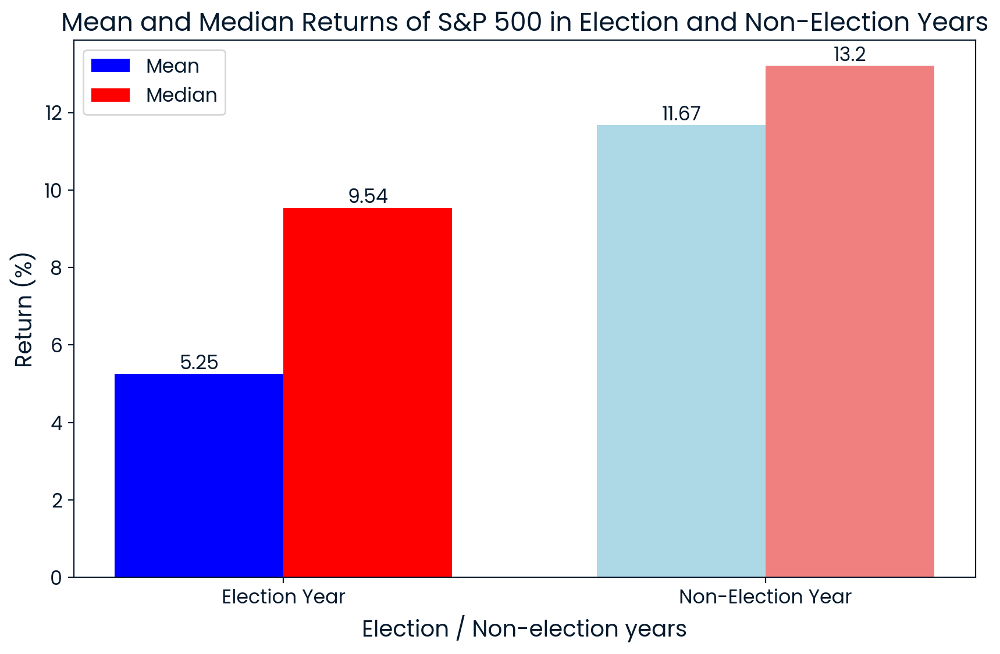

In [33]:
import matplotlib.pyplot as plt

# Data for plotting
categories = ['Election Year', 'Non-Election Year']
mean_returns = [mean_election_years * 100, mean_non_election_years * 100]
median_returns = [median_election_years * 100, median_non_election_years * 100]

# Create bar chart
plt.figure(figsize=(10, 6))
bar_width = 0.35
index = range(len(categories))

bars1 = plt.bar(index, mean_returns, bar_width, color=['blue', 'lightblue'], label='Mean')
bars2 = plt.bar([i + bar_width for i in index], median_returns, bar_width, color=['red', 'lightcoral'], label='Median')

# Add mean return values above each bar
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom', fontsize=12)

# Add median return values above each bar
for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom', fontsize=12)

plt.xlabel('Election / Non-election years', fontsize=14)
plt.ylabel('Return (%)', fontsize=14)
plt.title('Mean and Median Returns of S&P 500 in Election and Non-Election Years', fontsize=16)
plt.xticks([i + bar_width / 2 for i in index], categories, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)

plt.show()

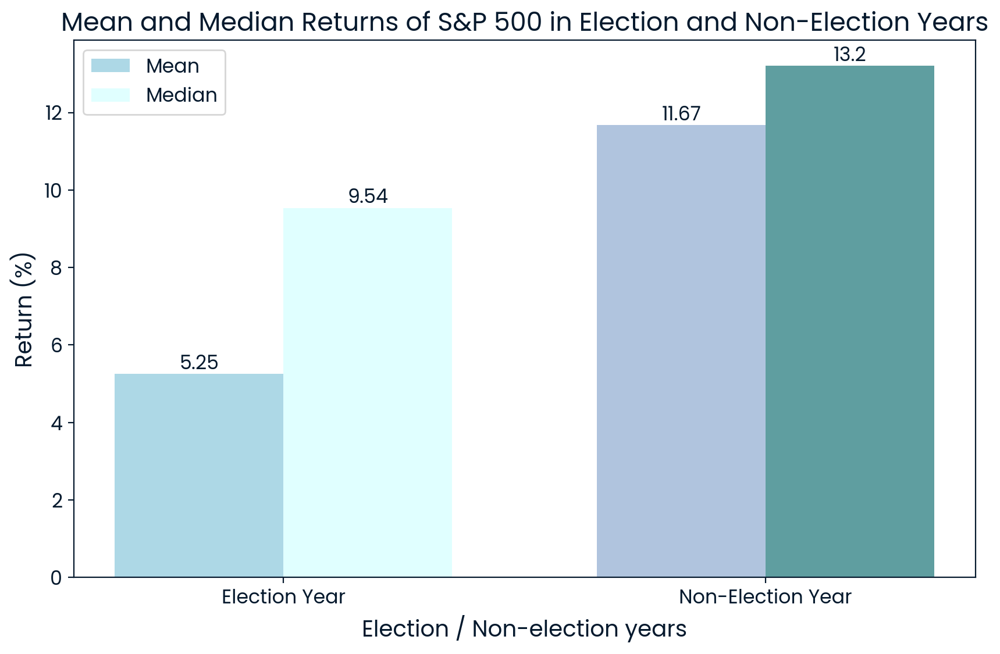

In [34]:
import matplotlib.pyplot as plt

# Data for plotting
categories = ['Election Year', 'Non-Election Year']
mean_returns = [mean_election_years * 100, mean_non_election_years * 100]
median_returns = [median_election_years * 100, median_non_election_years * 100]

# Create bar chart
plt.figure(figsize=(10, 6))
bar_width = 0.35
index = range(len(categories))

bars1 = plt.bar(index, mean_returns, bar_width, color=['lightblue', 'lightsteelblue'], label='Mean')
bars2 = plt.bar([i + bar_width for i in index], median_returns, bar_width, color=['lightcyan', 'cadetblue'], label='Median')

# Add mean return values above each bar
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom', fontsize=12)

# Add median return values above each bar
for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), ha='center', va='bottom', fontsize=12)

plt.xlabel('Election / Non-election years', fontsize=14)
plt.ylabel('Return (%)', fontsize=14)
plt.title('Mean and Median Returns of S&P 500 in Election and Non-Election Years', fontsize=16)
plt.xticks([i + bar_width / 2 for i in index], categories, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)

plt.show()

#### LASSO regularization helped us to shrink and eliminate the some predictors deemed less important and contribute less to the outcome, including election and interest rate.

#### Finalizing: In our research timeframe of 25 years (between 1990 and 2024), the election year has significantly lower mean and median returns than non-election years. This further justifies in detail that election is a determinant factor to market returns in the recent 25 years.

### Hypothesis 2: Fama French 3 Factors

In [35]:
import pandas as pd

# Import the factor return file
ff_data = pd.read_csv("F-F_Research_Data_Factors_daily.CSV",skiprows=4,parse_dates=['Date'], index_col='Date')
ff_data.columns = ['Mkt-RF', 'SMB', 'HML', 'RF']
ff_data = ff_data.div(100)

ff_data.index = pd.to_datetime(ff_data.index, errors='coerce')

# Extract data from 19900101 to 20241018
start_date = '1990-01-01'
end_date = '2024-10-18'
ff_data = ff_data[(ff_data.index >= start_date) & (ff_data.index <= end_date)]
print(ff_data.head())

            Mkt-RF     SMB     HML       RF
Date                                       
1990-01-02  0.0144 -0.0068 -0.0007  0.00026
1990-01-03 -0.0006  0.0073 -0.0026  0.00026
1990-01-04 -0.0071  0.0042 -0.0022  0.00026
1990-01-05 -0.0085  0.0077 -0.0021  0.00026
1990-01-08  0.0030 -0.0041 -0.0026  0.00026


In [36]:
# Inspect the dataframe with info
ff_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8733 entries, 1990-01-02 to 2024-08-30
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Mkt-RF  8733 non-null   float64
 1   SMB     8733 non-null   float64
 2   HML     8733 non-null   float64
 3   RF      8733 non-null   float64
dtypes: float64(4)
memory usage: 341.1 KB


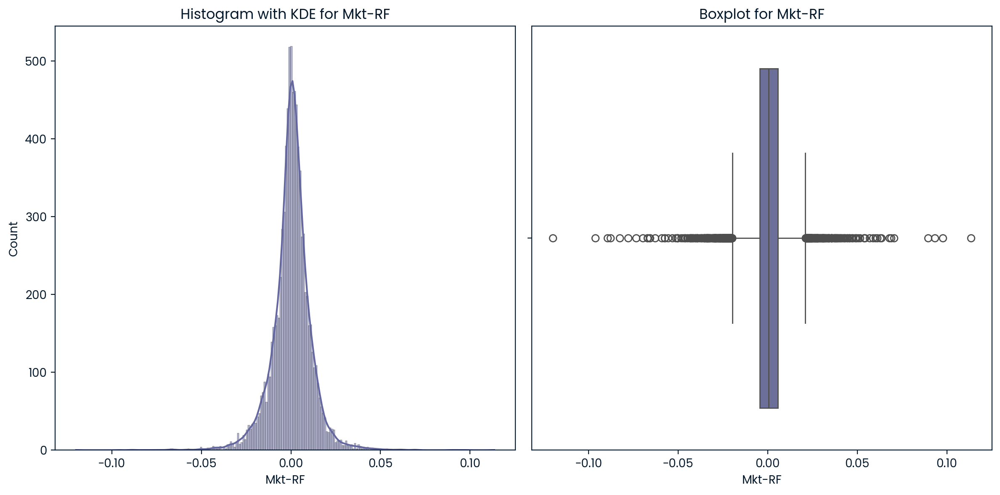

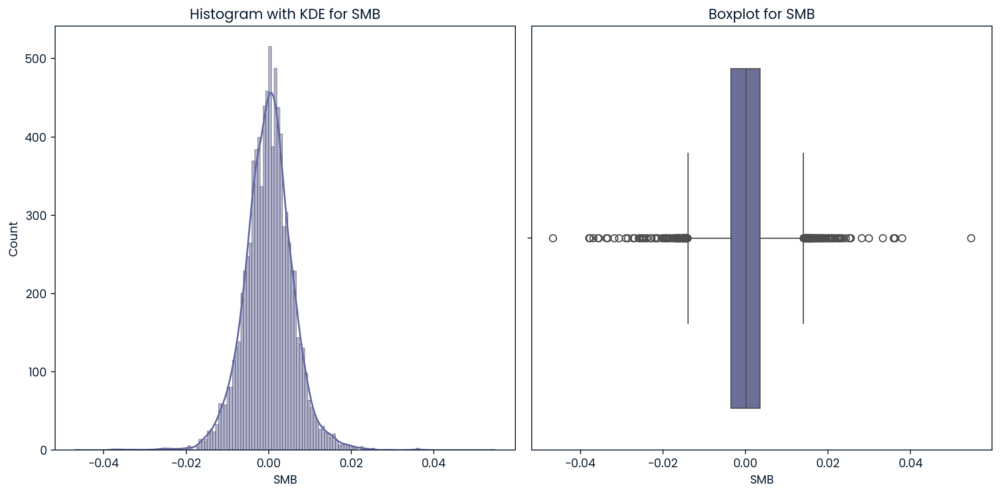

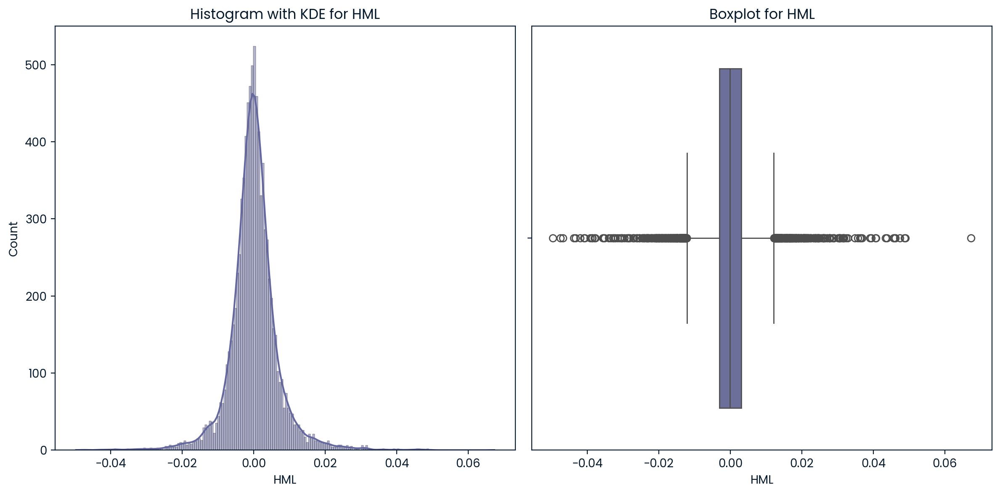

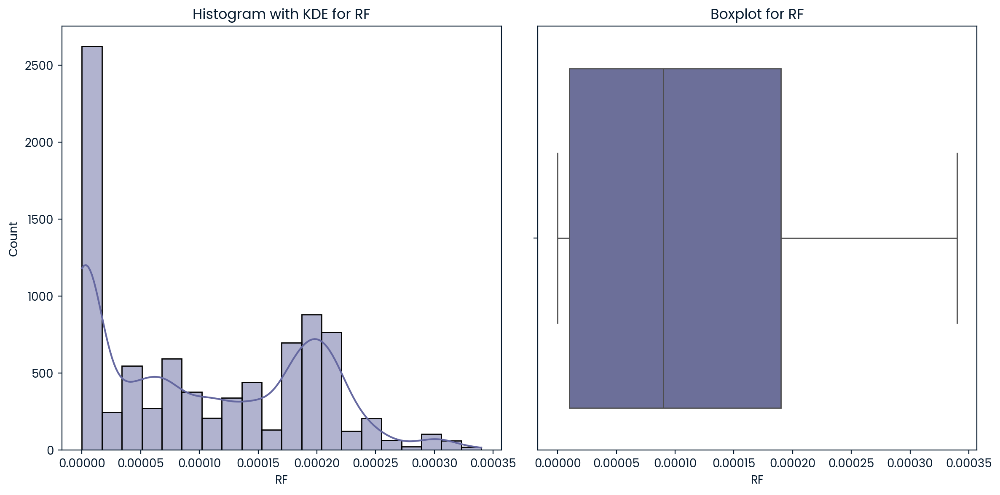

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Function to plot distribution check for each variable
def plot_distribution_check(data, column_name):
    plt.figure(figsize=(12, 6))
    
    # Histogram with KDE
    plt.subplot(1, 2, 1)
    sns.histplot(data[column_name], kde=True)
    plt.title(f'Histogram with KDE for {column_name}')
    
    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=data[column_name])
    plt.title(f'Boxplot for {column_name}')
    
    plt.tight_layout()
    plt.show()

# Example usage for each column in the daily_chg dataframe
for column in ff_data.columns:
    plot_distribution_check(ff_data, column)

In [38]:
# Ensure the 'Date' column in ff_data is a datetime object
ff_data.index = pd.to_datetime(ff_data.index)

# Ensure the 'DATE' column in daily_chg is a datetime object and set it as the index
daily_chg.index = pd.to_datetime(daily_chg.index)

# Merge the dataframes on their indices
merged_df = daily_chg.merge(ff_data, left_index=True, right_index=True, how='inner')

# Display the merged dataframe
print(merged_df)

'''
# Filter for election years
factors_election_years = merged_df[merged_df['election']==1]
factors_non_election_years = merged_df[merged_df['election']==0]
print(factors_election_years,factors_non_election_years)
'''

            log_sp500  election  incumbent_won  ...     SMB     HML       RF
1990-01-02   5.885243         0              1  ... -0.0068 -0.0007  0.00026
1990-01-03   5.882654         0              1  ...  0.0073 -0.0026  0.00026
1990-01-04   5.874003         0              1  ...  0.0042 -0.0022  0.00026
1990-01-05   5.864199         0              1  ...  0.0077 -0.0021  0.00026
1990-01-08   5.868704         0              1  ... -0.0041 -0.0026  0.00026
...               ...       ...            ...  ...     ...     ...      ...
2024-08-26   8.633524         1              0  ...  0.0010  0.0016  0.00022
2024-08-27   8.635118         1              0  ... -0.0086  0.0002  0.00022
2024-08-28   8.629125         1              0  ... -0.0055  0.0114  0.00022
2024-08-29   8.629085         1              0  ...  0.0038  0.0028  0.00022
2024-08-30   8.639128         1              0  ... -0.0055  0.0004  0.00022

[8733 rows x 11 columns]


"\n# Filter for election years\nfactors_election_years = merged_df[merged_df['election']==1]\nfactors_non_election_years = merged_df[merged_df['election']==0]\nprint(factors_election_years,factors_non_election_years)\n"

Election Years Factor Model Summary:
                            OLS Regression Results                            
Dep. Variable:              log_sp500   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.244
Date:                Fri, 08 Nov 2024   Prob (F-statistic):            0.00197
Time:                        05:43:05   Log-Likelihood:                -9352.7
No. Observations:                8733   AIC:                         1.872e+04
Df Residuals:                    8728   BIC:                         1.875e+04
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          

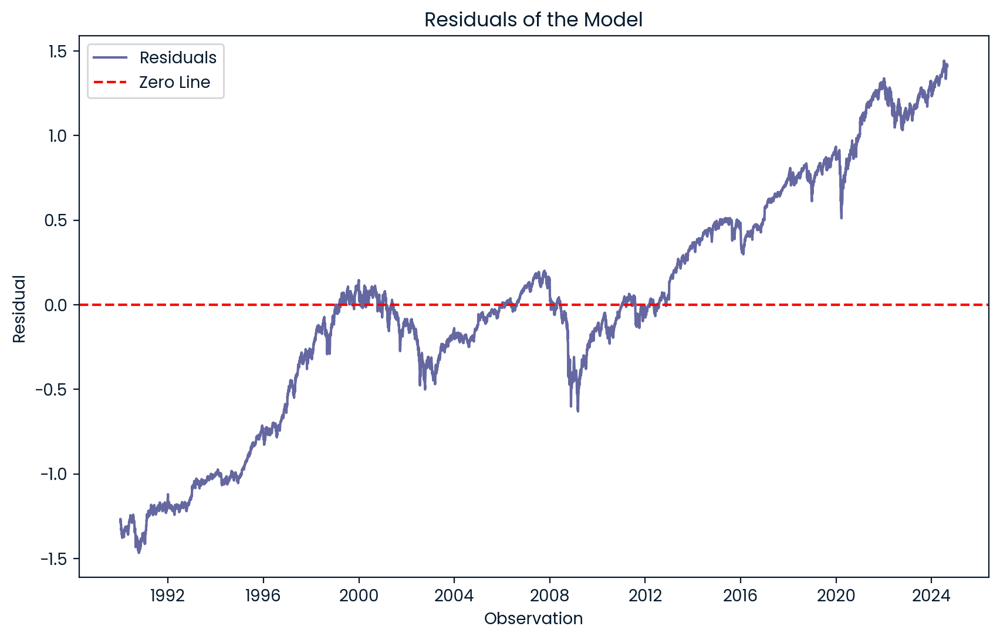

In [39]:
# Define your dependent variable (e.g., excess returns of a market index)
# and your factor variables for the models

# Running the model on election years
X_election = merged_df[['election','Mkt-RF', 'SMB', 'HML']]
y_election = merged_df['log_sp500']  
X_election = sm.add_constant(X_election)  
model_election = sm.OLS(y_election, X_election).fit(cov_type='HC3')
print("Election Years Factor Model Summary:")
print(model_election.summary())


# Calculate residuals
residuals = model_election.resid

# Output summary statistics of residuals
print("Residuals Summary:")
print(residuals.describe())

# Plot residuals
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(residuals, label='Residuals')
plt.axhline(0, color='red', linestyle='--', label='Zero Line')
plt.xlabel('Observation')
plt.ylabel('Residual')
plt.title('Residuals of the Model')
plt.legend()
plt.show()

***************************************************************************************

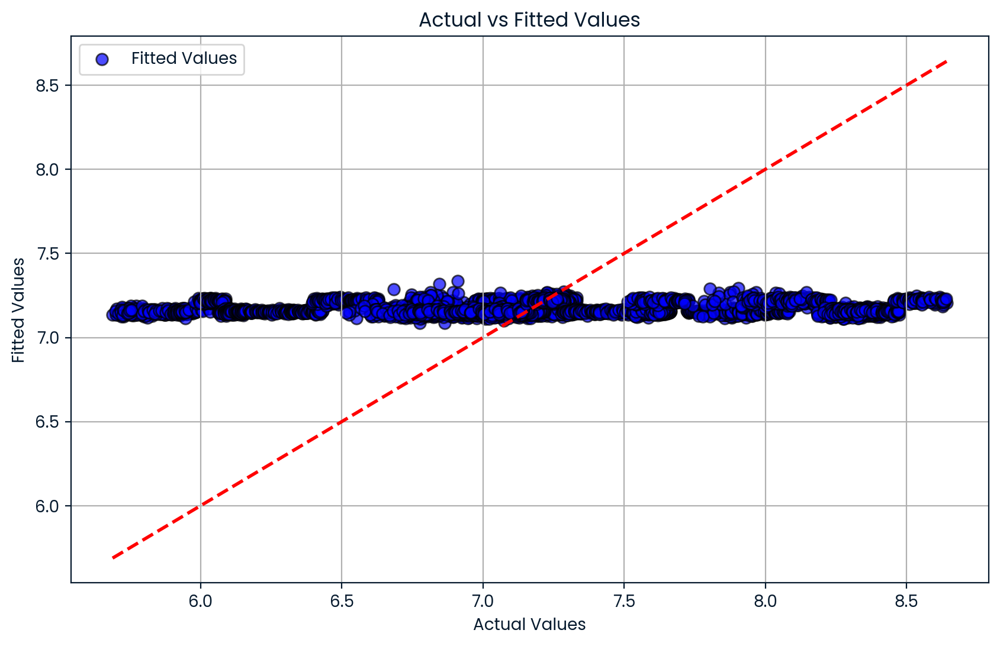

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Dummy data to mimic the user's actual and fitted values for demonstration purposes


fitted_values = model_election.fittedvalues
actual_values = y_election

# Plot the actual values vs. fitted values
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, fitted_values, edgecolor='k', alpha=0.7, s=50, label='Fitted Values', color='blue')
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Fitted Values')
plt.title('Actual vs Fitted Values')
plt.legend()
plt.grid(True)
plt.show()

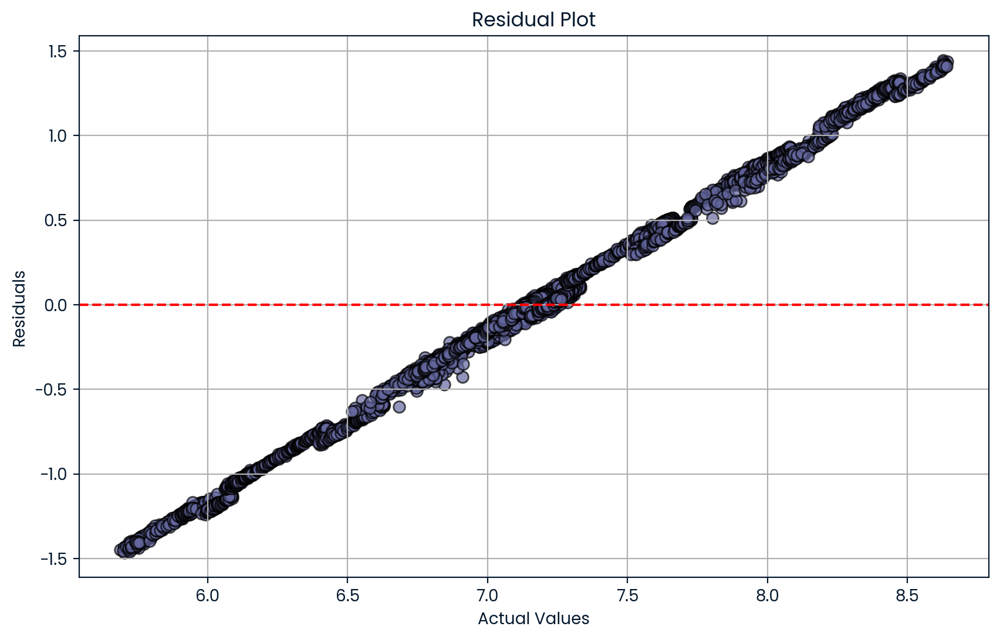

In [41]:
residuals = actual_values - fitted_values
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, residuals, edgecolor='k', alpha=0.7, s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True)
plt.show()

In [42]:
# Test multicollinearity by calculate VIF for each explanatory variable
vif_data = pd.DataFrame()
vif_data["feature"] = X_election.columns
vif_data["VIF"] = [variance_inflation_factor(X_election.values, i) for i in range(X_election.shape[1])]

# Display VIF data and F-test results
vif_data

,feature,VIF
0,const,1.335590
1,election,1.000570
2,Mkt-RF,1.005421
3,SMB,1.010639
4,HML,1.011509


In [43]:
import numpy as np
import statsmodels.api as sm

# Function to plot residual analysis plots for the whole model
def plot_residuals_analysis(model):
    residuals = model.resid
    
    plt.figure(figsize=(18, 12))
    
    # Q-Q plot
    plt.subplot(2, 2, 1)
    sm.qqplot(residuals, line='s', ax=plt.gca())
    plt.title('Q-Q plot for residuals of the model')
    
    # Histogram
    plt.subplot(2, 2, 2)
    sns.histplot(residuals, kde=True)
    plt.title('Histogram for residuals of the model')
    
    # Residuals vs Fitted
    plt.subplot(2, 2, 3)
    fitted_values = model.fittedvalues
    sns.scatterplot(x=fitted_values, y=residuals)
    plt.axhline(0, color='r', linestyle='--')
    plt.title('Residuals vs Fitted for the model')
    plt.xlabel('Fitted values')
    plt.ylabel('Residuals')
    
    # Scale-Location plot
    plt.subplot(2, 2, 4)
    sqrt_abs_residuals = np.sqrt(np.abs(residuals))
    sns.scatterplot(x=fitted_values, y=sqrt_abs_residuals)
    plt.axhline(0, color='r', linestyle='--')
    plt.title('Scale-Location plot for the model')
    plt.xlabel('Fitted values')
    plt.ylabel('Sqrt(|Residuals|)')
    
    plt.tight_layout()
    plt.show()

In [44]:
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.diagnostic import het_white
from statsmodels.stats.diagnostic import linear_harvey_collier

def test_assum(model):
    test_result_ele = het_breuschpagan(model.resid,model.model.exog)
    print('Lagrange multiplier statistic:', test_result_ele[0])
    print('p-value:', test_result_ele[1])
    # If the p-value is less than 0.05, we reject the null hypothesis of homoskedasticity
    if test_result_ele[1] < 0.05:
        print("Breusch-Pagan Test: The residuals are heteroskedastic (p < 0.05).")
    else:
        print("Breusch-Pagan Test: The residuals are homoskedastic (p >= 0.05).")
    
    # Calculate residuals
    residuals_ele = model.resid

    # Perform Shapiro-Wilk test for normality on the residuals
    shapiro_test_ele = stats.shapiro(residuals_ele)

    # Extract the test statistic and p-value
    shapiro_statistic_ele, shapiro_p_value_ele = shapiro_test_ele
    print(shapiro_test_ele)
    # If the p-value is less than 0.05, we reject the null hypothesis of normality
    if shapiro_p_value_ele < 0.05:
        print("Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).")
    else:
        print("Shapiro-Wilk Test: The residuals are normally distributed (p >= 0.05).")

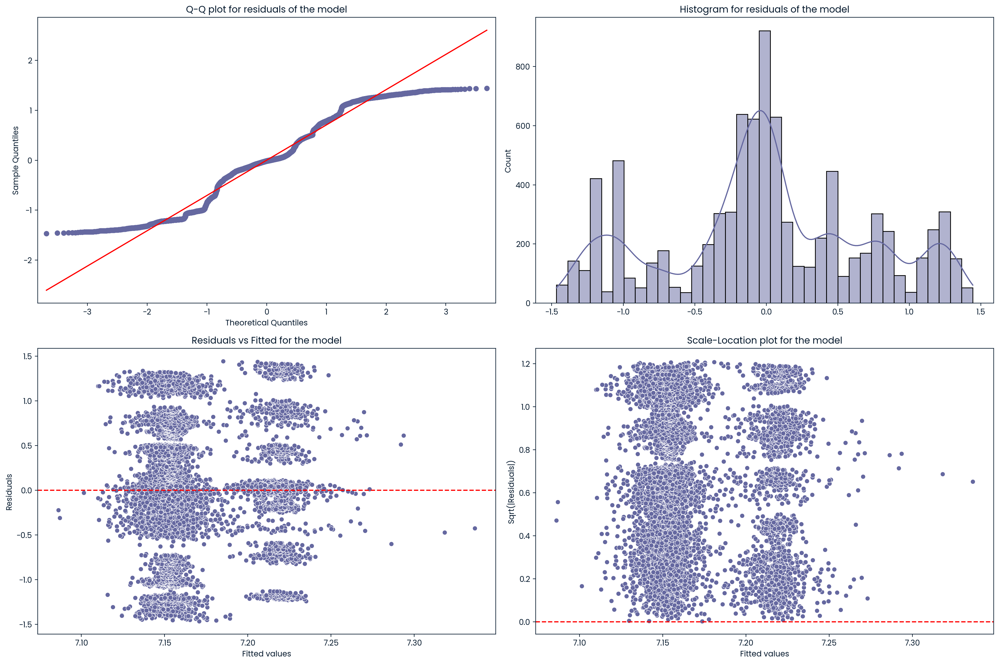

None
Lagrange multiplier statistic: 5.845901255165444
p-value: 0.21095582116214398
Breusch-Pagan Test: The residuals are homoskedastic (p >= 0.05).
ShapiroResult(statistic=0.9663166999816895, pvalue=6.006525737481896e-41)
Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).
None


In [45]:
print(plot_residuals_analysis(model_election))
print(test_assum(model_election))

(0.0002731698724044894, <Figure size 640x480 with 1 Axes>)

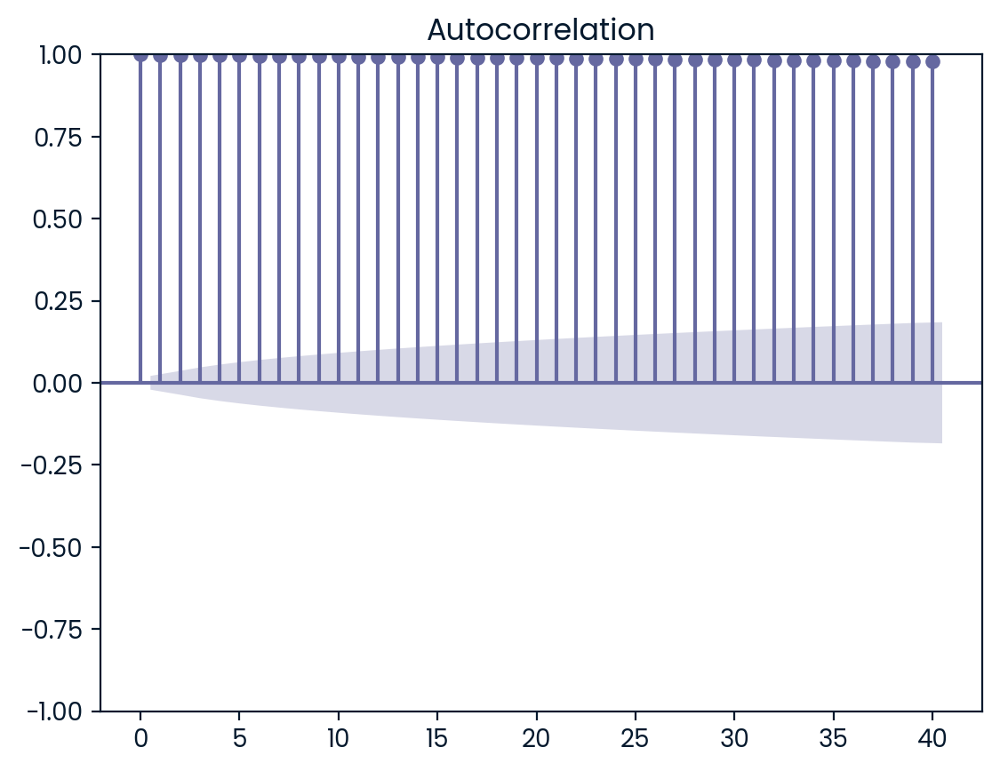

In [46]:
from statsmodels.stats.stattools import durbin_watson
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# Perform Durbin-Watson test on model3 residuals
dw_test_ele = durbin_watson(model_election.resid)

# Perform ACF test on model3 residuals
acf_test_ele = sm.graphics.tsa.plot_acf(model_election.resid, lags=40)

dw_test_ele, acf_test_ele

In [47]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

a=merged_df['Mkt-RF']
b=merged_df['SMB']
c=merged_df['HML']

# Define the unrestricted model
unrestricted_model = ols('log_sp500 ~ election +a + b + c', data=merged_df).fit(cov_type='HAC', cov_kwds={'maxlags':1})

# Define the restricted model (excluding election and incumbent_won)
restricted_model = ols('log_sp500 ~ a +b + c', data=merged_df).fit(cov_type='HAC', cov_kwds={'maxlags':1})
                         
# Perform F-test to compare the restricted and unrestricted models
anova_results = anova_lm(restricted_model, unrestricted_model)

# Display the ANOVA results
print(anova_results)

# Conclusion based on the p-value
if anova_results["Pr(>F)"][1] < 0.05:
    conclusion = "The unrestricted model is significantly better than the restricted model."
else:
    conclusion = "There is no significant difference between the restricted and unrestricted models."

# Additional conclusion
additional_conclusion = "The robust covariance treatment accounts for heteroskedasticity and autocorrelation, providing more reliable test results."

print(conclusion, additional_conclusion)

   df_resid          ssr  df_diff  ss_diff          F    Pr(>F)
0    8729.0  4361.561878      0.0      NaN        NaN       NaN
1    8728.0  4354.272108      1.0  7.28977  14.612113  0.000133
The unrestricted model is significantly better than the restricted model. The robust covariance treatment accounts for heteroskedasticity and autocorrelation, providing more reliable test results.


In [48]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
import numpy as np

# Define the features and target variable
# Check if 'const' column exists before dropping it
if 'const' in X.columns:
    X = X.drop(columns=['const'])
    y = merged_df['log_sp500']

# Ensure X and y have the same number of samples
X, y = X.align(y, join='inner', axis=0)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform LassoCV to find the best alpha
lasso_cv = LassoCV(cv=5, random_state=0).fit(X_scaled, y)

# Get the best alpha
best_alpha = lasso_cv.alpha_

# Fit the Lasso model with the best alpha
lasso_model = LassoCV(alphas=[best_alpha], cv=5, random_state=0).fit(X_scaled, y)

# Coefficients of the Lasso model
lasso_coefficients = lasso_model.coef_

# Intercept of the Lasso model
lasso_intercept = lasso_model.intercept_

# Display the results
lasso_coefficients, lasso_intercept, best_alpha

(array([ 0.01138086,  0.        , -0.04975745, -0.12697961,  0.61633382,
        -0.        ,  0.        ,  0.        ,  0.        ,  0.0122146 ,
         0.        ]),
 7.170275673164129,
 0.01652966600009087)

In [49]:
import statsmodels.api as sm

# Define the dependent variable Y
Y = merged_df['log_sp500']

# Define the independent variables X (including log_vix and interaction terms)
X = merged_df[['election','Mkt-RF', 'SMB', 'HML']]

# Create interaction terms
X['election*Mkt-RF'] = X['election'] * X['Mkt-RF']  
X['election*SMB'] = X['election'] * X['SMB']
X['election*HML'] = X['election'] * X['HML']

print(X)

# Add a constant to the independent variables
X = sm.add_constant(X)
print(X)

# Create the regression model using robust covariance for heteroskedasticity, autocorrelation, and multicollinearity
model_ele= sm.OLS(Y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 1})

# Display the summary of the regression model
model_ele.summary()

            election  Mkt-RF  ...  election*SMB  election*HML
1990-01-02         0  0.0144  ...       -0.0000       -0.0000
1990-01-03         0 -0.0006  ...        0.0000       -0.0000
1990-01-04         0 -0.0071  ...        0.0000       -0.0000
1990-01-05         0 -0.0085  ...        0.0000       -0.0000
1990-01-08         0  0.0030  ...       -0.0000       -0.0000
...              ...     ...  ...           ...           ...
2024-08-26         1 -0.0034  ...        0.0010        0.0016
2024-08-27         1  0.0006  ...       -0.0086        0.0002
2024-08-28         1 -0.0067  ...       -0.0055        0.0114
2024-08-29         1  0.0008  ...        0.0038        0.0028
2024-08-30         1  0.0098  ...       -0.0055        0.0004

[8733 rows x 7 columns]
            const  election  ...  election*SMB  election*HML
1990-01-02    1.0         0  ...       -0.0000       -0.0000
1990-01-03    1.0         0  ...        0.0000       -0.0000
1990-01-04    1.0         0  ...        0.0000  

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_sp500   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.951
Date:                Fri, 08 Nov 2024   Prob (F-statistic):             0.0578
Time:                        05:43:11   Log-Likelihood:                -9351.1
No. Observations:                8733   AIC:                         1.872e+04
Df Residuals:                    8725   BIC:                         1.877e+04
Df Model:                           7                                         
Covariance Type:                  HAC                                         
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               7.1521      0.012    575.404      0.000       7.128       7.176
election            0.0672      0.024      2.770      0.006       0.020       0.115
Mkt-RF              0.6472      0.764      0.848      0.397      -0.849       2.144
SMB                -0.5487      1.573     -0.349      0.727      -3.632       2.534
HML                 0.9591      1.606      0.597      0.550      -2.188       4.107
election*Mkt-RF     0.8077      1.100      0.734      0.463      -1.348       2.964
election*SMB       -0.0239      2.482     -0.010      0.992      -4.888       4.840
election*HML       -3.7142      2.349     -1.581      0.114      -8.319       0.890
==============================================================================
Omnibus:                      267.369   Durbin-Watson:                   0.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              127.924
Skew:                          -0.037   Prob(JB):                     1.67e-28
Kurtosis:                       2.412   Cond. No.                         389.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 1 lags and without small sample correction
"""

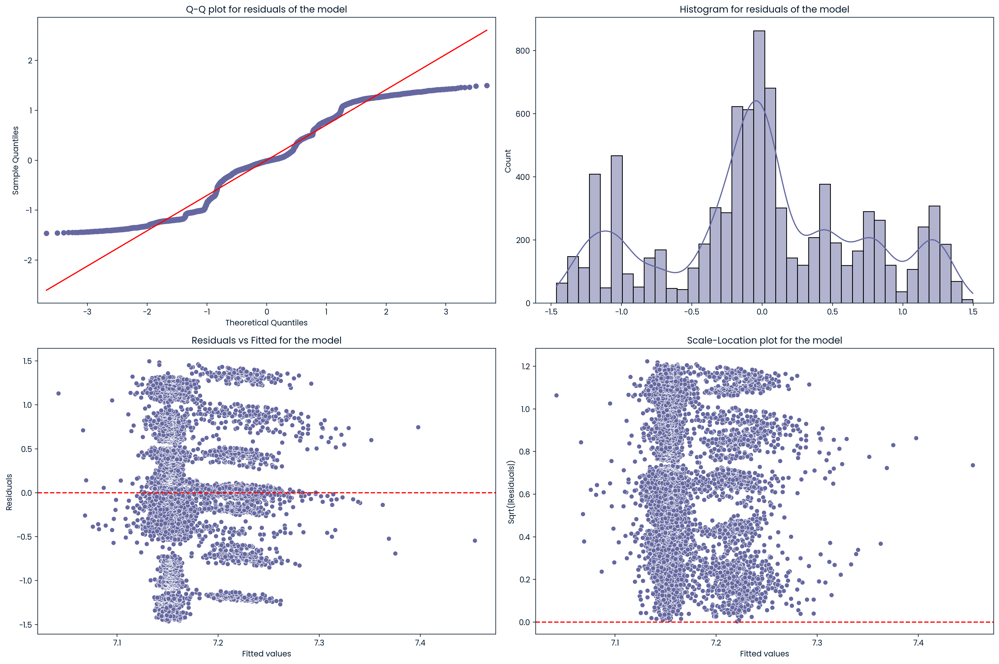

Lagrange multiplier statistic: 7.519721445619174
p-value: 0.37683980000039874
Breusch-Pagan Test: The residuals are homoskedastic (p >= 0.05).
ShapiroResult(statistic=0.9665829539299011, pvalue=7.978432936479778e-41)
Shapiro-Wilk Test: The residuals are not normally distributed (p < 0.05).


In [50]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
plot_residuals_analysis(model_ele)
test_assum(model_ele)